# 10 — Interpretabilidad del Modelo
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

Este notebook estudia **qué características usa el modelo final** seleccionado en el
notebook 08 (SVM lineal) mediante SHAP. No evalúa rendimiento: las métricas siguen siendo
las out-of-fold (OOF) del notebook 09.

### Decisión metodológica importante
El `SVC` multiclase usa **one-vs-one (OvO)** internamente. `shap.LinearExplainer` explica
los **tres hiperplanos pairwise**, no el score OvR ni probabilidades. El notebook verifica
esa correspondencia y etiqueta cada eje como:

| Eje SHAP | Margen pairwise | Positivo favorece |
|---|---|---|
| 0 | health vs sick | health |
| 1 | health vs tb | health |
| 2 | sick vs tb | sick |

Por tanto, la evidencia hacia `tb` es `-SHAP[:, :, 1]` y `-SHAP[:, :, 2]`.

### Estructura
1. Carga y verificación de artefactos.
2. Preparación del espacio de interpretación y verificación de SHAP.
3. SHAP global por margen pairwise.
4. Interpretación de `tb` frente a `health` y `sick`.
5. Importancia por familia de características.
6. Explicaciones individuales OOF con el modelo del fold correspondiente.
7. Limitaciones y discusión.


## 0. Configuración del entorno


In [1]:
# Se configura el path del proyecto y se importan las librerías necesarias.
# Referencias:
#   SHAP: https://shap.readthedocs.io/en/latest/
#   SVC lineal: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

import sys, os, warnings, json
warnings.filterwarnings('ignore')

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, recall_score

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.selection import build_selector
from src.visualization import set_publication_style

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_NAMES = ['health', 'sick', 'tb']
PAIR_LABELS = ['health vs sick', 'health vs tb', 'sick vs tb']

DATA_DIR    = Path('..') / 'data'
MODELS_DIR  = Path('..') / 'models'
REPORTS_DIR = Path('..') / 'reports'
REPORTS_DIR.mkdir(exist_ok=True)

set_publication_style()
print('Entorno configurado correctamente.')
print(f'SHAP {shap.__version__}')


Entorno configurado correctamente.
SHAP 0.54.1


## 1. Carga y verificación de artefactos


In [2]:
# Se comprueban los cuatro artefactos que deben ser compatibles:
#   08_svm.joblib, 08_manifest.json, 06_selected_feature_names.json,
#   08_oof_predicciones.csv (más X_full/y_full, scores y parámetros por fold).

ARCHIVOS = [
    DATA_DIR / 'X_full.npy',
    DATA_DIR / 'y_full.npy',
    DATA_DIR / 'features_tbx11k.csv',
    DATA_DIR / '06_selected_feature_names.json',
    DATA_DIR / '08_oof_predicciones.csv',
    DATA_DIR / '08_oof_scores.npz',
    DATA_DIR / '08_cv_por_fold.csv',
    MODELS_DIR / '08_svm.joblib',
    MODELS_DIR / '08_manifest.json',
]
for archivo in ARCHIVOS:
    if not archivo.exists():
        raise FileNotFoundError(f'No se encontró {archivo}. Ejecuta primero el notebook 08.')

modelo = joblib.load(MODELS_DIR / '08_svm.joblib')
selector = modelo.named_steps['selector']
scaler = modelo.named_steps['scaler']
clf = modelo.named_steps['clf']

print('Pipeline :', [paso[0] for paso in modelo.steps])
print('Selector :', type(selector).__name__, '| N =', selector.top_idx_.shape[0])
print('Escalador:', type(scaler).__name__)
print('Clasificador:', type(clf).__name__)
print('  kernel :', clf.kernel)
print('  C      :', clf.C)
print('  classes:', clf.classes_)
print('  coef_  :', clf.coef_.shape, '| intercept_ :', clf.intercept_.shape)
print('  decision_function_shape:', clf.decision_function_shape)

with open(MODELS_DIR / '08_manifest.json', encoding='utf-8') as f:
    manifest = json.load(f)
print()
print('Modelo seleccionado en 08:', manifest['seleccionado_cv'])
print('Selector en 08:', manifest['selector'])
print('Parámetros SVM:', manifest['mejores_params']['SVM'])

# Correspondencia exacta de las 1000 features.
feat_cols = pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0).columns.tolist()
feat_cols = [c for c in feat_cols if c not in ('image_path', 'class_name', 'label')]
pipeline_names = [feat_cols[i] for i in selector.top_idx_]
with open(DATA_DIR / '06_selected_feature_names.json', encoding='utf-8') as f:
    names_06 = json.load(f)

if pipeline_names != names_06:
    raise ValueError('Las features del pipeline no coinciden, en orden, con el notebook 06.')

print()
print('Features: pipeline y 06 coinciden en conjunto y orden (1000).')
print('Primeras 5:', pipeline_names[:5])

X_full = np.load(DATA_DIR / 'X_full.npy')
y_full = np.load(DATA_DIR / 'y_full.npy')
oof = pd.read_csv(DATA_DIR / '08_oof_predicciones.csv')
scores = np.load(DATA_DIR / '08_oof_scores.npz')
fold_params = pd.read_csv(DATA_DIR / '08_cv_por_fold.csv')

if not np.array_equal(oof['y_true'].to_numpy(), y_full):
    raise ValueError('y_true del OOF no coincide con y_full.')
if scores['SVM'].shape != (len(y_full), len(CLASS_NAMES)):
    raise ValueError('Los scores OOF del SVM no tienen la forma esperada.')

print()
print(f'X_full: {X_full.shape} | y_full: {y_full.shape}')
print(f'OOF SVM: BalAcc={balanced_accuracy_score(y_full, oof["SVM"]):.4f} | '
      f'Recall tb={recall_score(y_full, oof["SVM"], labels=[2], average=None)[0]:.4f}')
print('Score SVM OOF: min=%.4f, max=%.4f (funciones de decisión, no probabilidades)'
      % (float(scores['SVM'].min()), float(scores['SVM'].max())))
print()
print('Parámetros SVM por fold:')
print(fold_params[fold_params['Modelo'] == 'SVM'][['Fold', 'Mejores params']].to_string(index=False))


Pipeline : ['selector', 'scaler', 'clf']
Selector : RFTopNSelector | N = 1000
Escalador: StandardScaler
Clasificador: SVC
  kernel : linear
  C      : 0.003
  classes: [0 1 2]
  coef_  : (3, 1000) | intercept_ : (3,)
  decision_function_shape: ovr

Modelo seleccionado en 08: SVM
Selector en 08: {'metodo': 'RF', 'n_features': 1000}
Parámetros SVM: {'clf__C': 0.003}



Features: pipeline y 06 coinciden en conjunto y orden (1000).
Primeras 5: ['gabor_f0.4_t90_std', 'lbp_1', 'gabor_f0.3_t90_std', 'lbp_25', 'mean']



X_full: (8274, 3300) | y_full: (8274,)


OOF SVM: BalAcc=0.9494 | Recall tb=0.8950
Score SVM OOF: min=-0.3100, max=2.3109 (funciones de decisión, no probabilidades)

Parámetros SVM por fold:
 Fold    Mejores params
    1 {"clf__C": 0.003}
    2 {"clf__C": 0.003}
    3 {"clf__C": 0.003}
    4 {"clf__C": 0.003}
    5 {"clf__C": 0.003}


## 2. Preparación del espacio de interpretación y verificación de SHAP


In [3]:
# Se trabaja sobre una muestra estratificada de 500 imágenes por clase para que el
# cálculo sea reproducible y manejable. El modelo explicado es el final (8274 imágenes).
# Referencia: https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html

N_POR_CLASE = 500
rng = np.random.RandomState(RANDOM_STATE)

idx = []
for clase in np.unique(y_full):
    idx_clase = np.where(y_full == clase)[0]
    idx.extend(rng.choice(idx_clase, size=N_POR_CLASE, replace=False))
idx = np.array(idx)

X_sample = X_full[idx]
y_sample = y_full[idx]
X_sample_sc = scaler.transform(selector.transform(X_sample))

feature_names = pipeline_names


def grupo_feature(nombre):
    """Asigna cada característica a una familia del extractor."""
    if nombre.startswith('hog_'):
        return 'HOG'
    if nombre.startswith('phog_'):
        return 'PHOG'
    if nombre.startswith('gabor_'):
        return 'Gabor'
    if nombre.startswith('lbp_'):
        return 'LBP'
    if nombre.startswith('glcm_'):
        return 'GLCM'
    if nombre in ('mean', 'std', 'contrast', 'entropy'):
        return 'Intensidad global'
    if nombre[:2] in ('SI', 'SD', 'MI', 'MD', 'II', 'ID'):
        return 'Intensidad regional'
    return 'Otra'


GRUPOS = ['HOG', 'PHOG', 'GLCM', 'LBP', 'Gabor', 'Intensidad global', 'Intensidad regional']
grupos_por_feature = [grupo_feature(n) for n in feature_names]
conteo_grupos = pd.Series(grupos_por_feature).value_counts().reindex(GRUPOS).fillna(0).astype(int)

print('Composición de las 1000 features seleccionadas:')
print(conteo_grupos.to_string())

# Fondo de referencia estratificado para LinearExplainer.
bg_idx = []
for clase in np.unique(y_sample):
    idx_clase = np.where(y_sample == clase)[0]
    bg_idx.extend(rng.choice(idx_clase, size=min(33, len(idx_clase)), replace=False))
background = X_sample_sc[np.array(bg_idx)]

explainer = shap.LinearExplainer(clf, background)
sv = explainer(X_sample_sc)

print()
print(f'SHAP values: {sv.values.shape}  (muestras, features, pares)')
print(f'base_values: {sv.base_values.shape}')
print('Ejes:', dict(zip(range(3), PAIR_LABELS)))

# Verificación: LinearExplainer explica los hiperplanos OvO, no el score OvR.
shap_sum = sv.base_values + sv.values.sum(axis=1)
ovo = (clf.coef_ @ X_sample_sc.T + clf.intercept_[:, None]).T
decision_ovr = clf.decision_function(X_sample_sc)

print()
print('Verificación de la correspondencia:')
print('  max |SHAP - (coef @ x + intercept)| :', float(np.max(np.abs(shap_sum - ovo))))
print('  max |SHAP - decision_function OvR| :', float(np.max(np.abs(shap_sum - decision_ovr))))
if not np.allclose(shap_sum, ovo, atol=1e-5):
    raise ValueError('SHAP no coincide con los hiperplanos OvO; no se puede interpretar como pairwise.')
print('  -> SHAP explica los márgenes pairwise OvO. No son probabilidades ni el score OvR.')

# Verificación formal de la orientación de cada par: para (i, j), el margen
# debe ser positivo en muestras de i y negativo en muestras de j.
print()
print('Verificación de orientación de los márgenes pairwise:')
pares_idx = [(0, 1), (0, 2), (1, 2)]
for par, (i, j) in enumerate(pares_idx):
    margen = clf.coef_[par] @ X_sample_sc.T + clf.intercept_[par]
    frac_i = float(np.mean(margen[y_sample == i] > 0))
    frac_j = float(np.mean(margen[y_sample == j] < 0))
    print(f'  {PAIR_LABELS[par]}: P(>0 | {CLASS_NAMES[i]})={frac_i:.4f}, '
          f'P(<0 | {CLASS_NAMES[j]})={frac_j:.4f}')


Composición de las 1000 features seleccionadas:
HOG                    476
PHOG                   441
GLCM                    10
LBP                     25
Gabor                   32
Intensidad global        3
Intensidad regional     13



SHAP values: (1500, 1000, 3)  (muestras, features, pares)
base_values: (1500, 3)
Ejes: {0: 'health vs sick', 1: 'health vs tb', 2: 'sick vs tb'}



Verificación de la correspondencia:
  max |SHAP - (coef @ x + intercept)| : 1.7133706453620334e-07
  max |SHAP - decision_function OvR| : 8.541120434030237
  -> SHAP explica los márgenes pairwise OvO. No son probabilidades ni el score OvR.

Verificación de orientación de los márgenes pairwise:
  health vs sick: P(>0 | health)=0.9960, P(<0 | sick)=0.9920
  health vs tb: P(>0 | health)=0.9960, P(<0 | tb)=1.0000
  sick vs tb: P(>0 | sick)=0.9740, P(<0 | tb)=0.9940


## 3. SHAP global por margen pairwise



--- health vs sick ---
           feature  mean_abs_shap grupo
             lbp_2       0.105230   LBP
            lbp_12       0.091496   LBP
             lbp_1       0.081151   LBP
            lbp_22       0.078551   LBP
            lbp_11       0.055981   LBP
            lbp_25       0.054507   LBP
             lbp_3       0.050167   LBP
            lbp_21       0.048179   LBP
          hog_1045       0.045502   HOG
       phog_l1_127       0.045054  PHOG
            lbp_20       0.044902   LBP
             lbp_0       0.044172   LBP
glcm_contrast_mean       0.044127  GLCM
          hog_1679       0.041156   HOG
            hog_88       0.041145   HOG
Solapamiento top-20 SHAP / coeficientes: 16/20

--- health vs tb ---
            feature  mean_abs_shap grupo
             lbp_12       0.110632   LBP
             lbp_21       0.108575   LBP
              lbp_2       0.106307   LBP
             lbp_11       0.105873   LBP
             lbp_20       0.105739   LBP
 gabor_f0.1_t90_std  

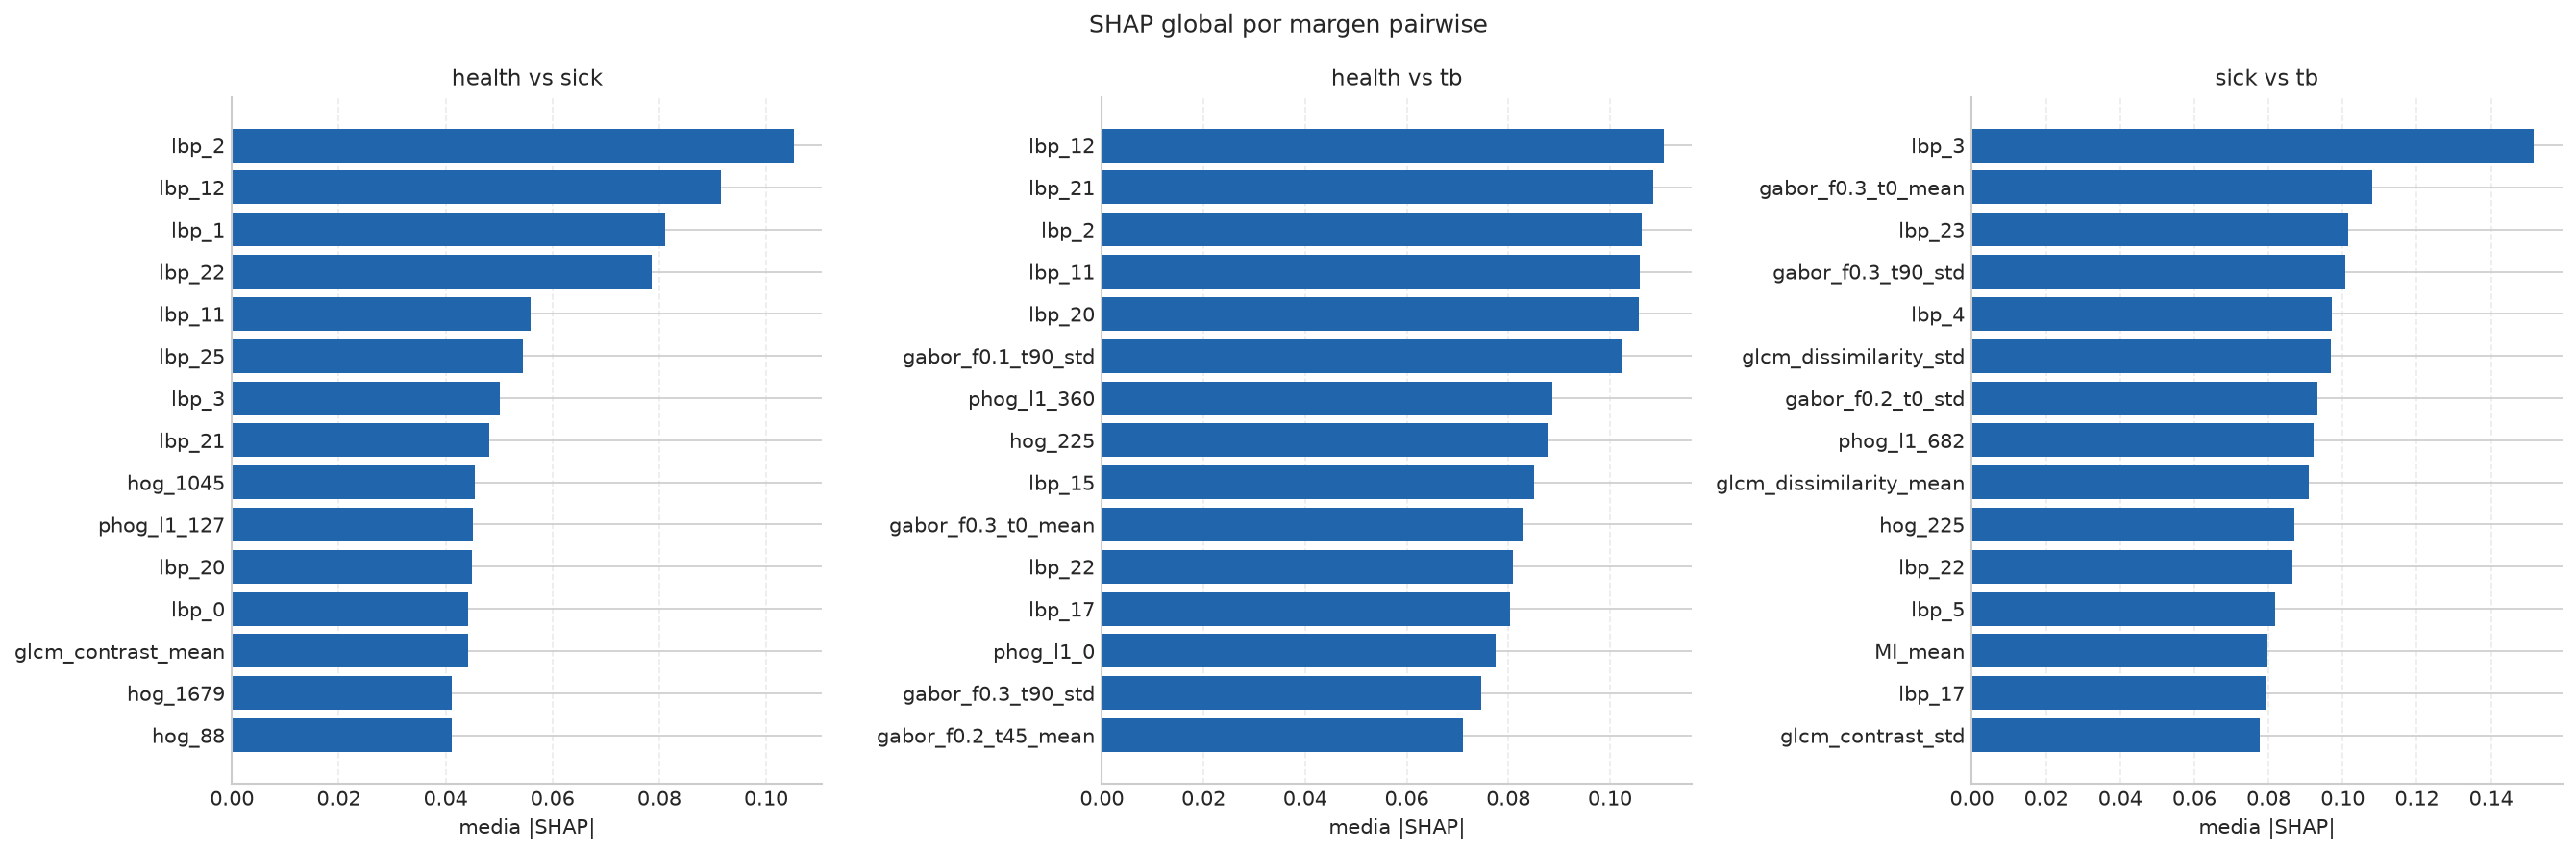

In [4]:
# Importancia global: media de |SHAP| sobre las muestras, para cada margen pairwise.
# Se contrasta con los coeficientes del SVM (misma fila de coef_ para cada par).

abs_sv = np.abs(sv.values)  # (n, features, 3)
coef = clf.coef_

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for par, ax in enumerate(axes):
    imp = abs_sv[:, :, par].mean(axis=0)
    top = np.argsort(imp)[::-1][:15]

    tabla = pd.DataFrame({
        'feature': [feature_names[i] for i in top],
        'mean_abs_shap': imp[top],
        'grupo': [grupo_feature(feature_names[i]) for i in top],
    })
    print()
    print(f'--- {PAIR_LABELS[par]} ---')
    print(tabla.round(6).to_string(index=False))

    # Control con coeficientes del mismo hiperplano.
    top_coef = set(np.argsort(np.abs(coef[par]))[::-1][:20])
    top_shap = set(np.argsort(imp)[::-1][:20])
    print(f'Solapamiento top-20 SHAP / coeficientes: {len(top_shap & top_coef)}/20')

    ax.barh(
        [feature_names[i] for i in top][::-1],
        imp[top][::-1],
        color='#2166AC',
    )
    ax.set_title(PAIR_LABELS[par], fontsize=11)
    ax.set_xlabel('media |SHAP|', fontsize=10)
    ax.grid(True, axis='x', linestyle='--', alpha=0.4)

fig.suptitle('SHAP global por margen pairwise', fontsize=12)
fig.tight_layout()
plt.show()


## 4. Magnitud de contribución hacia cada clase

> La tabla usa **|SHAP orientado|**: mide magnitud de contribución en los márgenes
> relevantes para cada clase, no evidencia neta. La dirección se conserva en los
> valores firmados de las explicaciones individuales (sección 6).



--- Magnitud de contribución hacia health ---
           feature  mean_abs_evidencia grupo
             lbp_2            0.105768   LBP
            lbp_12            0.101064   LBP
            lbp_11            0.080927   LBP
            lbp_22            0.079681   LBP
            lbp_21            0.078377   LBP
            lbp_20            0.075321   LBP
             lbp_1            0.071032   LBP
gabor_f0.1_t90_std            0.061241 Gabor
            lbp_15            0.060410   LBP
gabor_f0.3_t0_mean            0.059201 Gabor
         phog_l1_0            0.059024  PHOG
            lbp_25            0.056778   LBP
            lbp_17            0.056474   LBP
             hog_0            0.055422   HOG
           hog_225            0.053913   HOG

--- Magnitud de contribución hacia sick ---
                feature  mean_abs_evidencia grupo
                  lbp_3            0.100872   LBP
                  lbp_2            0.085022   LBP
                 lbp_22            0.0

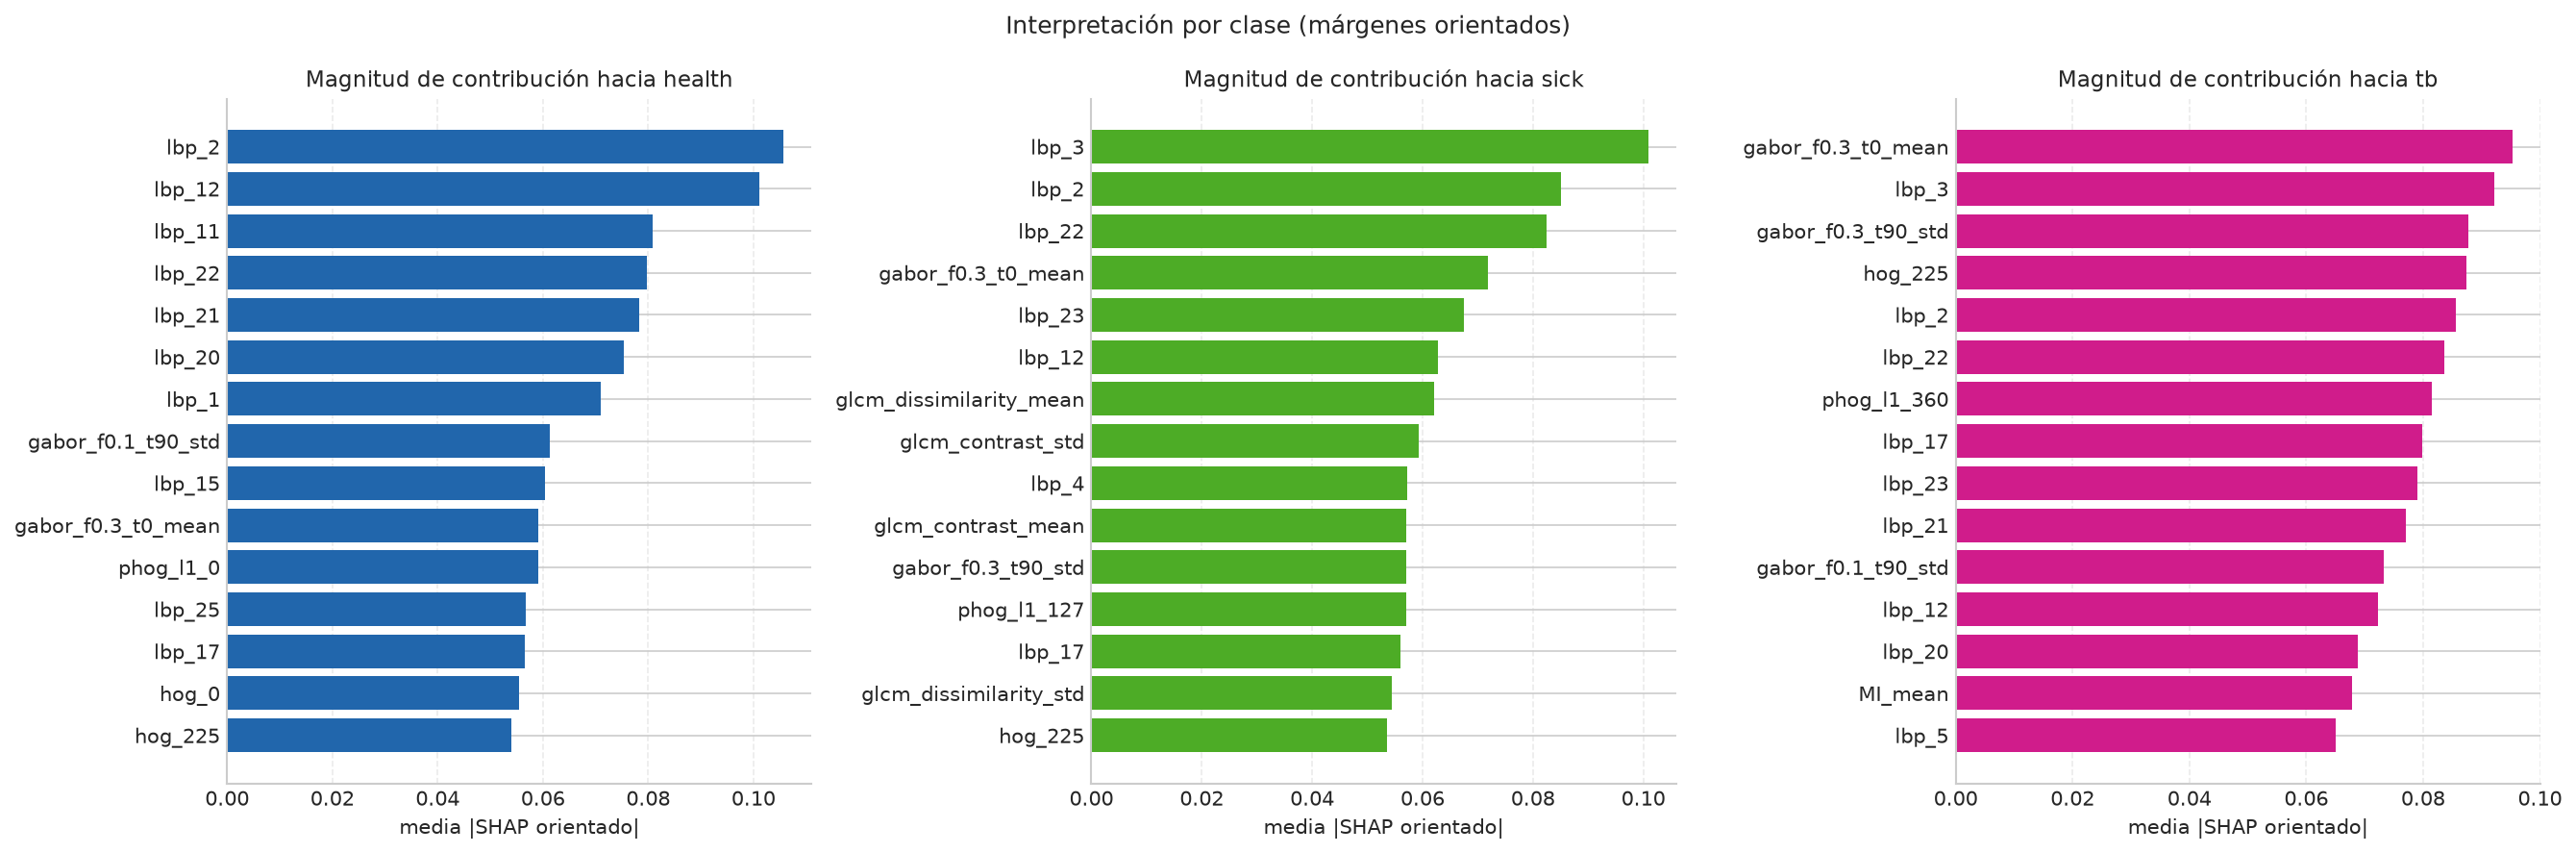

In [5]:
# Evidencia hacia cada clase, orientando los márgenes:
#   health: +SHAP par 0 (health vs sick), +SHAP par 1 (health vs tb)
#   sick  : -SHAP par 0 (sick vs health), +SHAP par 2 (sick vs tb)
#   tb    : -SHAP par 1 (tb vs health), -SHAP par 2 (tb vs sick)

EVIDENCIA = {
    'health': [(0, +1), (1, +1)],
    'sick':   [(0, -1), (2, +1)],
    'tb':     [(1, -1), (2, -1)],
}


def importancia_clase(clase):
    """Media de |evidencia| por feature para una clase, sobre sus pares relevantes."""
    valores = np.stack([
        signo * sv.values[:, :, par] for par, signo in EVIDENCIA[clase]
    ], axis=-1)
    return np.abs(valores).mean(axis=(0, 2))


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, clase in zip(axes, CLASS_NAMES):
    imp = importancia_clase(clase)
    top = np.argsort(imp)[::-1][:15]

    tabla = pd.DataFrame({
        'feature': [feature_names[i] for i in top],
        'mean_abs_evidencia': imp[top],
        'grupo': [grupo_feature(feature_names[i]) for i in top],
    })
    print()
    print(f'--- Magnitud de contribución hacia {clase} ---')
    print(tabla.round(6).to_string(index=False))

    ax.barh(
        [feature_names[i] for i in top][::-1],
        imp[top][::-1],
        color={'health': '#2166AC', 'sick': '#4DAC26', 'tb': '#D01C8B'}[clase],
    )
    ax.set_title(f'Magnitud de contribución hacia {clase}', fontsize=11)
    ax.set_xlabel('media |SHAP orientado|', fontsize=10)
    ax.grid(True, axis='x', linestyle='--', alpha=0.4)

fig.suptitle('Interpretación por clase (márgenes orientados)', fontsize=12)
fig.tight_layout()
plt.show()


## 5. Importancia por familia de características


Importancia media por feature y familia:
Clase                  health      sick        tb
Grupo                                            
HOG                  0.011685  0.013684  0.015579
PHOG                 0.011703  0.014279  0.016423
GLCM                 0.020637  0.041737  0.036186
LBP                  0.047317  0.043406  0.051379
Gabor                0.025634  0.025710  0.036389
Intensidad global    0.019687  0.023699  0.026150
Intensidad regional  0.020737  0.025415  0.032314


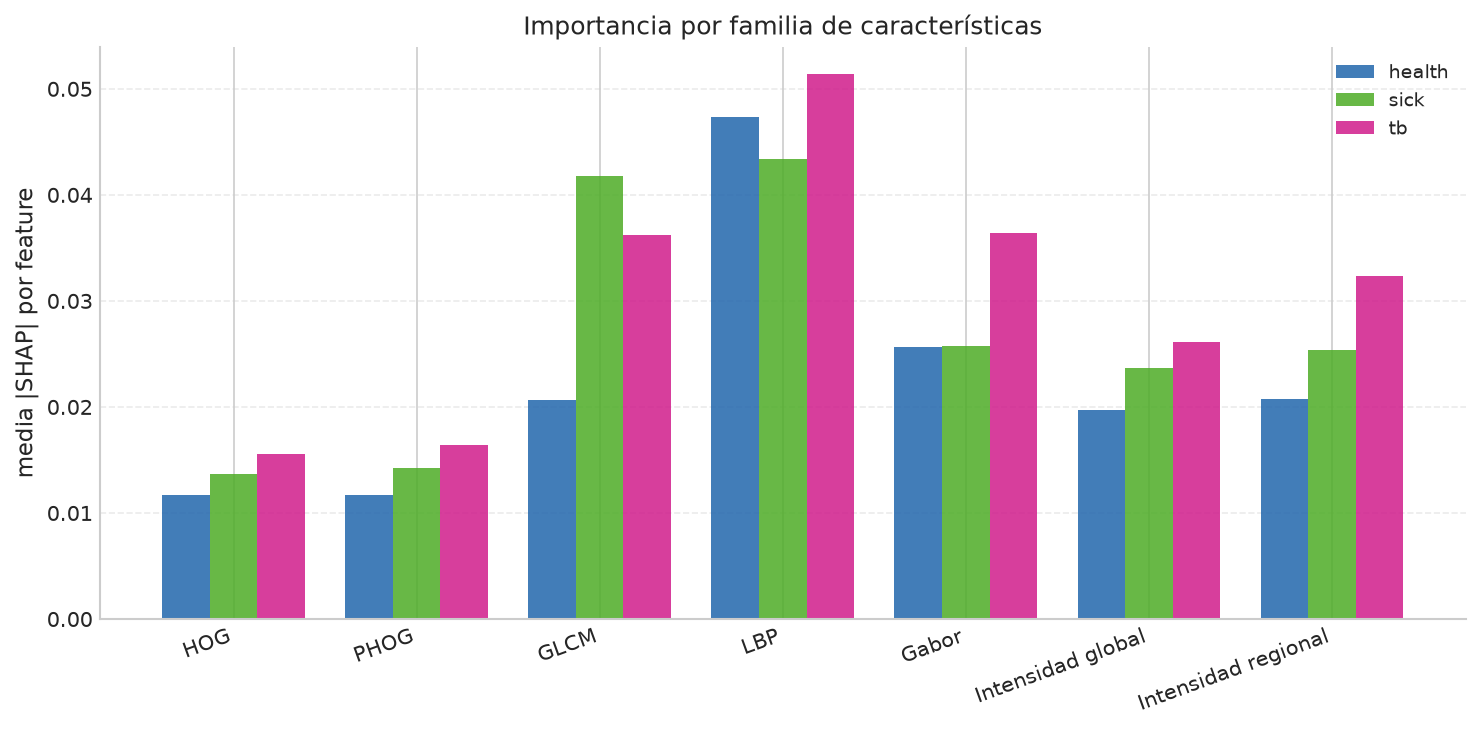


Nota: el total por familia favorece a HOG/PHOG por tener más columnas;
la comparación justa entre familias es la media por feature.


In [6]:
# Se agrega la importancia por familia. Se reporta la media por feature (justa entre
# familias con distinto número de columnas) y el total por familia.

def importancia_grupo(imp_vec):
    filas = []
    for grupo in GRUPOS:
        idx_grupo = [i for i, g in enumerate(grupos_por_feature) if g == grupo]
        if not idx_grupo:
            continue
        filas.append({
            'Grupo': grupo,
            'n_features': len(idx_grupo),
            '%_features': 100 * len(idx_grupo) / len(feature_names),
            'media_por_feature': float(np.mean(imp_vec[idx_grupo])),
            'total_grupo': float(np.sum(imp_vec[idx_grupo])),
        })
    return pd.DataFrame(filas)


tablas = []
for clase in CLASS_NAMES:
    df_clase = importancia_grupo(importancia_clase(clase))
    df_clase['Clase'] = clase
    tablas.append(df_clase)

tabla_grupos = pd.concat(tablas, ignore_index=True)
print('Importancia media por feature y familia:')
print(tabla_grupos.pivot(index='Grupo', columns='Clase', values='media_por_feature')
      .reindex(GRUPOS).round(6).to_string())

# Gráfico de barras agrupadas (media por feature).
pivote = tabla_grupos.pivot(index='Grupo', columns='Clase', values='media_por_feature').reindex(GRUPOS)
x = np.arange(len(pivote.index))
ancho = 0.26
fig, ax = plt.subplots(figsize=(10, 5))
for k, clase in enumerate(CLASS_NAMES):
    ax.bar(x + (k - 1) * ancho, pivote[clase], ancho,
           label=clase,
           color={'health': '#2166AC', 'sick': '#4DAC26', 'tb': '#D01C8B'}[clase],
           alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(pivote.index, rotation=20, ha='right')
ax.set_ylabel('media |SHAP| por feature', fontsize=11)
ax.set_title('Importancia por familia de características', fontsize=12)
ax.legend(fontsize=9)
ax.grid(True, axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()

print()
print('Nota: el total por familia favorece a HOG/PHOG por tener más columnas;')
print('la comparación justa entre familias es la media por feature.')


## 6. Explicaciones individuales OOF


In [7]:
# Para explicar estrictamente un error OOF se reconstruye el modelo del fold que
# generó esa predicción: mismo split, mismo selector y mismos parámetros guardados.
# El modelo final (8274) se usa para el análisis global, no para estas explicaciones.

cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv_outer.split(X_full, y_full))
fold_of_index = {}
for fold, (tr_idx, va_idx) in enumerate(folds, start=1):
    for i in va_idx:
        fold_of_index[int(i)] = fold

params_por_fold = {
    int(fila['Fold']): json.loads(fila['Mejores params'])
    for _, fila in fold_params[fold_params['Modelo'] == 'SVM'].iterrows()
}

fold_cache = {}


def obtener_modelo_fold(fold):
    """Reconstruye el modelo SVM del fold (selector + escalador + SVC)."""
    if fold in fold_cache:
        return fold_cache[fold]

    tr_idx, va_idx = folds[fold - 1]
    params = params_por_fold[fold]
    C = params.get('clf__C', 0.003)

    selector_f = build_selector('RF', 1000, random_state=RANDOM_STATE, n_jobs=-1)
    selector_f.fit(X_full[tr_idx], y_full[tr_idx])
    X_tr = selector_f.transform(X_full[tr_idx])
    scaler_f = StandardScaler().fit(X_tr)
    X_tr_sc = scaler_f.transform(X_tr)

    clf_f = SVC(
        kernel='linear', class_weight='balanced', C=C,
        cache_size=500, decision_function_shape='ovr',
        random_state=RANDOM_STATE,
    )
    clf_f.fit(X_tr_sc, y_full[tr_idx])

    fold_cache[fold] = (selector_f, scaler_f, clf_f, X_tr_sc, va_idx)
    return fold_cache[fold]


y_true = oof['y_true'].to_numpy()
pred_svm = oof['SVM'].to_numpy()

casos = {
    'tb correcto': np.where((y_true == 2) & (pred_svm == 2))[0],
    'tb falso negativo': np.where((y_true == 2) & (pred_svm != 2))[0],
    'tb falso positivo': np.where((y_true != 2) & (pred_svm == 2))[0],
}

seleccion = {nombre: int(rng.choice(indices)) for nombre, indices in casos.items()}

for etiqueta, idx_ejemplo in seleccion.items():
    fold = fold_of_index[idx_ejemplo]
    selector_f, scaler_f, clf_f, X_tr_sc, va_idx = obtener_modelo_fold(fold)

    x_raw_sel = selector_f.transform(X_full[[idx_ejemplo]])
    x_sc = scaler_f.transform(x_raw_sel)
    pred_fold = int(clf_f.predict(x_sc)[0])

    bg_fold = X_tr_sc[rng.choice(len(X_tr_sc), size=min(100, len(X_tr_sc)), replace=False)]
    explainer_f = shap.LinearExplainer(clf_f, bg_fold)
    sv_i = explainer_f(x_sc)

    nombres_fold = [feat_cols[i] for i in selector_f.top_idx_]
    clase_pred = CLASS_NAMES[pred_fold]

    print('=' * 72)
    print(f'{etiqueta} | índice={idx_ejemplo} | fold={fold}')
    print(f'  real={CLASS_NAMES[int(y_true[idx_ejemplo])]} | '
          f'OOF={CLASS_NAMES[int(pred_svm[idx_ejemplo])]} | fold={clase_pred}')
    if pred_fold != int(pred_svm[idx_ejemplo]):
        print('  ADVERTENCIA: la predicción reconstruida no coincide con la OOF.')

    pares = EVIDENCIA[clase_pred]
    for par, signo in pares:
        contrib = signo * sv_i.values[0, :, par]
        top = np.argsort(np.abs(contrib))[::-1][:8]

        tabla = pd.DataFrame({
            'feature': [nombres_fold[i] for i in top],
            'shap_orientado': contrib[top],
            'valor_feature': x_raw_sel[0, top],
        })
        print(f'  Margen {PAIR_LABELS[par]} (orientado a {clase_pred}):')
        print(tabla.round(4).to_string(index=False))


tb correcto | índice=7960 | fold=5
  real=tb | OOF=tb | fold=tb
  Margen health vs tb (orientado a tb):
           feature  shap_orientado  valor_feature
             lbp_2          0.1980         0.0126
          hog_1520         -0.1830         0.4675
       phog_l1_360          0.1757         0.2217
           hog_225          0.1629         0.2120
gabor_f0.3_t0_mean          0.1146         0.6678
             lbp_1          0.1053         0.0098
            hog_21          0.1025         0.0472
          hog_1605         -0.0813         0.0272
  Margen sick vs tb (orientado a tb):
           feature  shap_orientado  valor_feature
           hog_225          0.1958       0.212000
 gabor_f0.4_t0_std          0.1818       0.947400
       phog_l1_360          0.1677       0.221700
gabor_f0.3_t0_mean          0.1447       0.667800
 gabor_f0.3_t0_std          0.1407       0.929400
            II_std         -0.1404      47.878899
             lbp_4          0.1317       0.011600
        

tb falso negativo | índice=8242 | fold=2
  real=tb | OOF=health | fold=health
  Margen health vs sick (orientado a health):
    feature  shap_orientado  valor_feature
    hog_227         -0.1070         0.2302
  phog_l1_0         -0.0995         0.2755
      hog_0         -0.0970         0.2735
phog_l1_214          0.0829         0.2869
     lbp_22         -0.0655         0.0072
     lbp_21         -0.0594         0.0098
     lbp_20         -0.0558         0.0120
     SD_std         -0.0553        55.2883
  Margen health vs tb (orientado a health):
     feature  shap_orientado  valor_feature
   phog_l1_0         -0.1428         0.2755
       hog_0         -0.1281         0.2735
phog_l1_1008         -0.1177         0.0156
      lbp_21         -0.1137         0.0098
      lbp_20         -0.1120         0.0120
     hog_225         -0.0958         0.1411
 phog_l1_360         -0.0916         0.1409
 phog_l1_990         -0.0895         0.0422
tb falso positivo | índice=5491 | fold=5
  real=s

## 7. Atribución espacial y cajas de lesión

TBX11K incluye cajas de lesión para las imágenes de TB. Aquí se enlazan con `full_meta.csv`
y se calculan **mapas de oclusión** sobre una rejilla 8×8: se tapa cada celda, se vuelve a
extraer el vector de 3300 features y se mide cuánto cae el score multiclase de TB. Un valor
positivo indica que esa zona sostiene la predicción de TB.

Es una sensibilidad por oclusión, **no SHAP**: sirve para comprobar si la atribución cae
sobre la lesión anotada. Se usan tres imágenes de TB correctamente clasificadas.


Imágenes de TB con cajas: 169
Candidatas TB correctas con caja: 142
Ejemplos: ['tb0003.png', 'tb0007.png', 'tb0017.png']


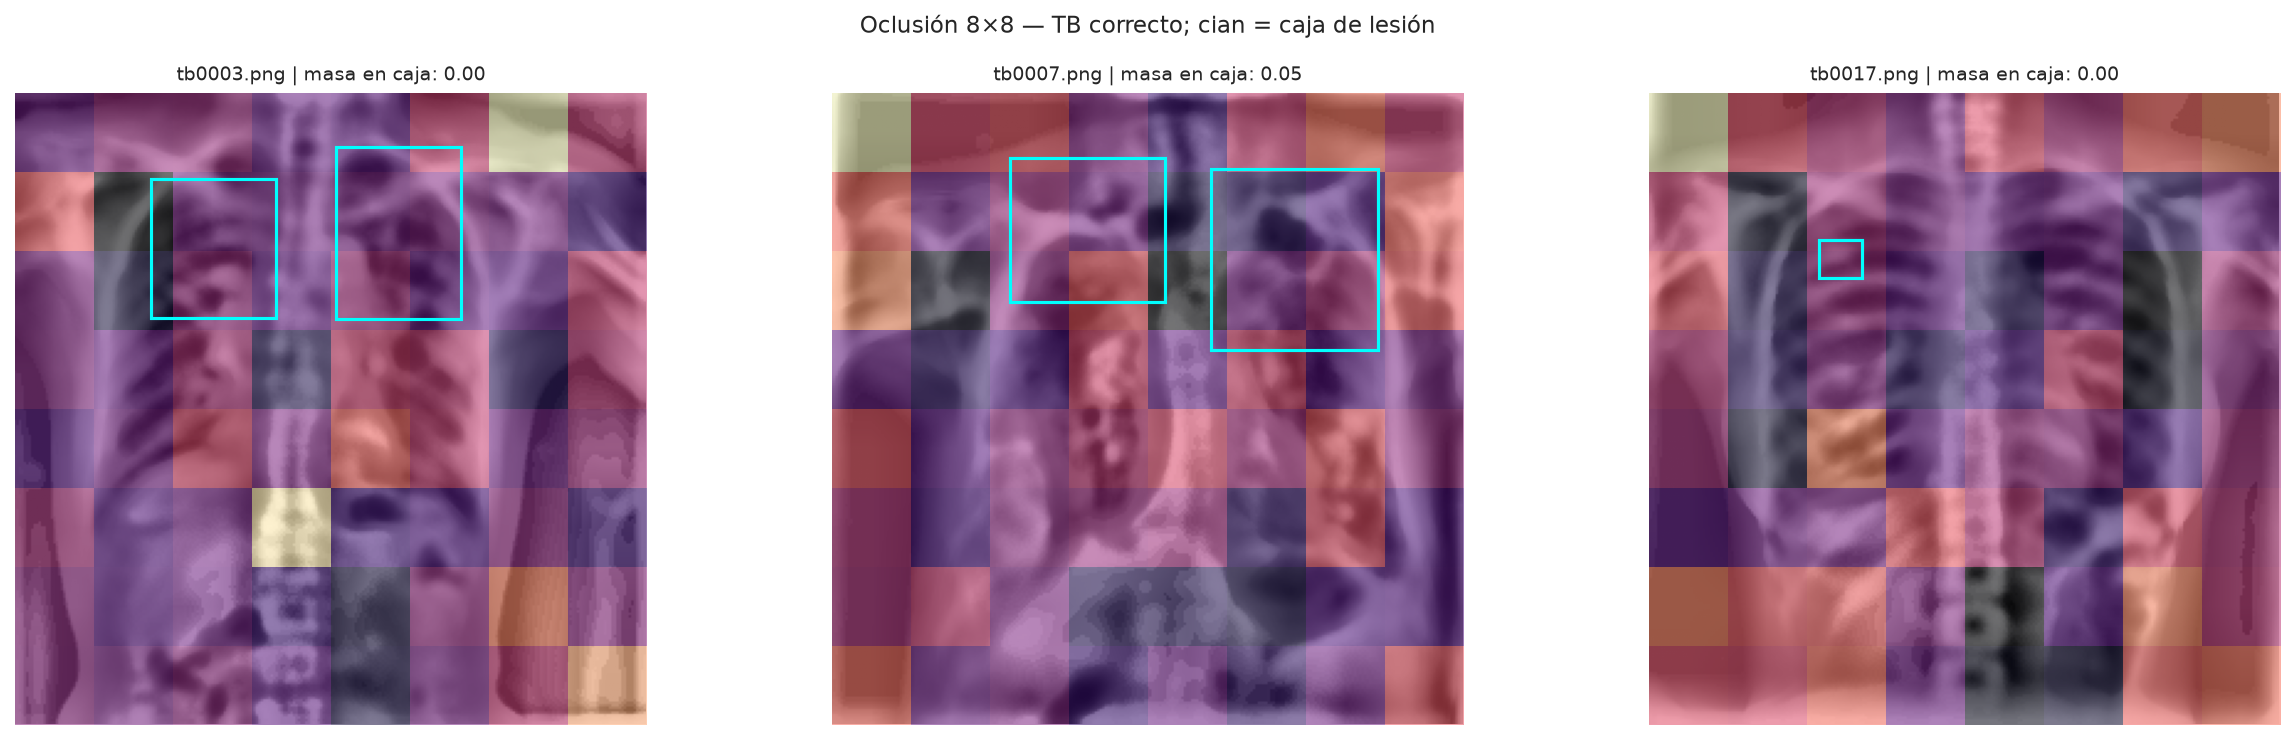

In [8]:
# Enlace de cajas de lesión y mapas de oclusión 8x8.
# Referencia COCO: https://cocodataset.org/#format-data

import json
import tempfile
import cv2
from matplotlib.patches import Rectangle

from src.features import extract_features
from src.preprocessing import preprocess

coco_path = Path('..') / 'data' / 'TBX11K' / 'annotations' / 'json' / 'TBX11K_trainval.json'
if not coco_path.exists():
    raise FileNotFoundError(f'No se encontró {coco_path}')

with open(coco_path, encoding='utf-8') as f:
    coco = json.load(f)

meta = pd.read_csv(DATA_DIR / 'full_meta.csv')
basename_to_idx = {Path(p).name: i for i, p in enumerate(meta['image_path'])}
imagenes_coco = {img['id']: img['file_name'] for img in coco['images']}
cat_tb = [c['id'] for c in coco['categories']
          if c['name'].lower() in ('tb', 'tuberculosis')]
cat_tb = cat_tb[0] if cat_tb else 2

cajas = {}
for ann in coco['annotations']:
    if ann.get('category_id') != cat_tb:
        continue
    file_name = imagenes_coco.get(ann['image_id'])
    if file_name is None:
        continue
    idx = basename_to_idx.get(Path(file_name).name)
    if idx is None:
        continue
    path = meta.loc[idx, 'image_path']
    cajas.setdefault(path, []).append(tuple(float(v) for v in ann['bbox']))

print(f'Imágenes de TB con cajas: {len(cajas)}')

oof_les = pd.read_csv(DATA_DIR / '08_oof_predicciones.csv')
mask_tb = (oof_les['y_true'] == 2) & (oof_les['SVM'] == 2)
paths_tb_ok = set(meta.loc[mask_tb.to_numpy(), 'image_path'])
candidatos = sorted(set(cajas) & paths_tb_ok)
print(f'Candidatas TB correctas con caja: {len(candidatos)}')

if not candidatos:
    raise ValueError('No hay imágenes de TB correctas con caja para analizar.')

ejemplos = candidatos[:3]
print('Ejemplos:', [Path(p).name for p in ejemplos])

feat_cols = pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0).columns.tolist()
feat_cols = [c for c in feat_cols if c not in ('image_path', 'class_name', 'label')]

GRID = 8
fig, axes = plt.subplots(1, len(ejemplos), figsize=(5.5 * len(ejemplos), 5))
if len(ejemplos) == 1:
    axes = [axes]

for ax, path in zip(axes, ejemplos):
    idx = int(meta.index[meta['image_path'] == path][0])
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    x_base = X_full[[idx]]
    score_base = clf.decision_function(
        scaler.transform(selector.transform(x_base))
    )[0, 2]

    heatmap = np.zeros((GRID, GRID), dtype=float)
    h, w = img.shape
    cell_h, cell_w = h // GRID, w // GRID

    for gy in range(GRID):
        for gx in range(GRID):
            occ = img.copy()
            y0, y1 = gy * cell_h, (gy + 1) * cell_h
            x0, x1 = gx * cell_w, (gx + 1) * cell_w
            occ[y0:y1, x0:x1] = 0

            with tempfile.NamedTemporaryFile(suffix='.png', delete=False) as tmp:
                tmp_path = tmp.name
            cv2.imwrite(tmp_path, occ)
            try:
                f = extract_features(tmp_path, 2, 'tb')
                vec = np.array([f[k] for k in feat_cols], dtype=np.float32).reshape(1, -1)
                score = clf.decision_function(
                    scaler.transform(selector.transform(vec))
                )[0, 2]
                heatmap[gy, gx] = score_base - score
            finally:
                Path(tmp_path).unlink(missing_ok=True)

    # Fracción de masa positiva dentro de las cajas anotadas.
    cajas_img = cajas[path]
    inside = 0.0
    total = 0.0
    for gy in range(GRID):
        for gx in range(GRID):
            drop = max(heatmap[gy, gx], 0.0)
            total += drop
            cx = gx * cell_w + cell_w / 2
            cy = gy * cell_h + cell_h / 2
            if any(x <= cx <= x + bw and y <= cy <= y + bh
                   for x, y, bw, bh in cajas_img):
                inside += drop
    fraccion = inside / total if total > 0 else float('nan')

    img_256 = preprocess(path)
    ax.imshow(img_256, cmap='gray')
    ax.imshow(heatmap, extent=[0, 256, 256, 0], cmap='magma', alpha=0.55)
    for x, y, bw, bh in cajas_img:
        ax.add_patch(Rectangle((x * 0.5, y * 0.5), bw * 0.5, bh * 0.5,
                               fill=False, edgecolor='cyan', linewidth=1.5))
    ax.set_title(f'{Path(path).name} | masa en caja: {fraccion:.2f}', fontsize=9)
    ax.axis('off')

fig.suptitle('Oclusión 8×8 — TB correcto; cian = caja de lesión', fontsize=11)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '10_oclusion_lesiones.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Limitaciones y discusión


## Conclusiones

El modelo final es un SVM lineal y SHAP explica sus **tres márgenes pairwise OvO**, no
probabilidades ni el score OvR. La verificación numérica de la sección 2 confirma esa
correspondencia.

Las 1000 features seleccionadas están dominadas por HOG (476) y PHOG (441), pero la
importancia media por feature es mayor en LBP y, para TB, también en Gabor y GLCM:

- **health vs sick**: LBP domina (`lbp_2`, `lbp_12`, `lbp_1`, `lbp_22`); después aparecen
  HOG/PHOG y GLCM.
- **health vs tb**: LBP + Gabor + PHOG/HOG; aparecen `gabor_f0.1_t90_std` y
  `gabor_f0.3_t0_mean`.
- **sick vs tb**: LBP + Gabor + GLCM (`glcm_dissimilarity_std`, `glcm_contrast_std`).

En la magnitud de contribución orientada a TB los primeros lugares son Gabor (`gabor_f0.3_t0_mean`,
`gabor_f0.3_t90_std`), varias columnas LBP, HOG/PHOG y `MI_mean` (intensidad regional).
La media por familia confirma que LBP es la familia con mayor importancia por feature;
Gabor es la segunda para TB; GLCM pesa más en sick; HOG/PHOG aportan muchas columnas pero
con menor importancia individual.

El solapamiento entre las features dominantes de SHAP y los coeficientes del SVM es alto
(16/20, 17/20 y 18/20 para los tres márgenes), lo que respalda la coherencia de la
interpretación.

En los ejemplos individuales, el TB correcto se apoya en LBP/HOG/PHOG/Gabor; el falso
negativo presenta evidencia hacia health en HOG/PHOG; el falso positivo (real sick,
predicho tb) se apoya en LBP/Gabor y en contra de TB en algunas columnas LBP. Son
explicaciones del modelo del fold correspondiente, no del modelo final.

No se observa un dominio global de intensidad/contraste, aunque `MI_mean` aparece en la
evidencia hacia TB y conviene vigilarlo. La interpretación es asociativa: SHAP no
demuestra causalidad y las features correlacionadas comparten atribución.

**Atribución espacial y lesiones (3 ejemplos TB correctos).** La masa de oclusión dentro
de las cajas anotadas fue **0.00, 0.05 y 0.00**. El modelo no concentra su evidencia en la
lesión; la atribución se distribuye por regiones amplias. Sumado al baseline de solo
fondo/borde del notebook 09 (BalAcc **0.8797 LR / 0.8919 SVM**), esto apunta a una
dependencia de contexto/adquisición y no a una lectura localizada de la lesión. La tesis de
interpretabilidad clínica no queda sostenida sin segmentación pulmonar y validación externa.

**Verificación de signo.** La orientación de los pares se confirmó con las medias por clase:
`P(>0|health)=0.996` y `P(<0|sick)=0.992` para health vs sick; `0.996` y `1.000` para
health vs tb; `0.974` y `0.994` para sick vs tb. Los márgenes están correctamente
etiquetados.


**Fin del pipeline de modelado, evaluación e interpretabilidad.**
